# 06 · Interpretación (Fases 8 y 9)
Dos miradas independientes: (1) un modelo explicativo ponderado con errores robustos por diseño muestral, y (2) importancia por permutación del modelo predictivo. Si coinciden, la evidencia converge.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *
df = pd.read_parquet(PROCESSED / "emovi_movilidad.parquet")
q1 = df[df.sigue_q1.notna()]
from src.models import train as T
tr, te = T.split(df)
tabla, modelos = T.compare(tr, te, T.NUM, T.CAT)
elegido, mejor_auc = T.choose(tabla)
modelo = modelos[elegido]
from src.evaluation import interpret as I
from src.visualization import plots as V
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


,Razón de momios,IC 95% inf,IC 95% sup,p-valor
educ_madre = No sabe / ausente,0.746,0.442,1.257,0.271
educ_madre = Secundaria o más,0.724,0.417,1.258,0.252
educ_padre = No sabe / ausente,1.572,1.050,2.353,0.028
educ_padre = Secundaria o más,0.978,0.553,1.729,0.939
localidad_14 = Ciudad chica,0.478,0.176,1.300,0.148
localidad_14 = Ciudad grande,0.471,0.156,1.423,0.182
localidad_14 = Ciudad mediana,0.467,0.165,1.318,0.150
"localidad_14 = Pueblo (<2,500)",0.771,0.303,1.966,0.586
region_14 = Centro-norte,0.574,0.326,1.012,0.055
region_14 = Norte,0.398,0.192,0.825,0.013


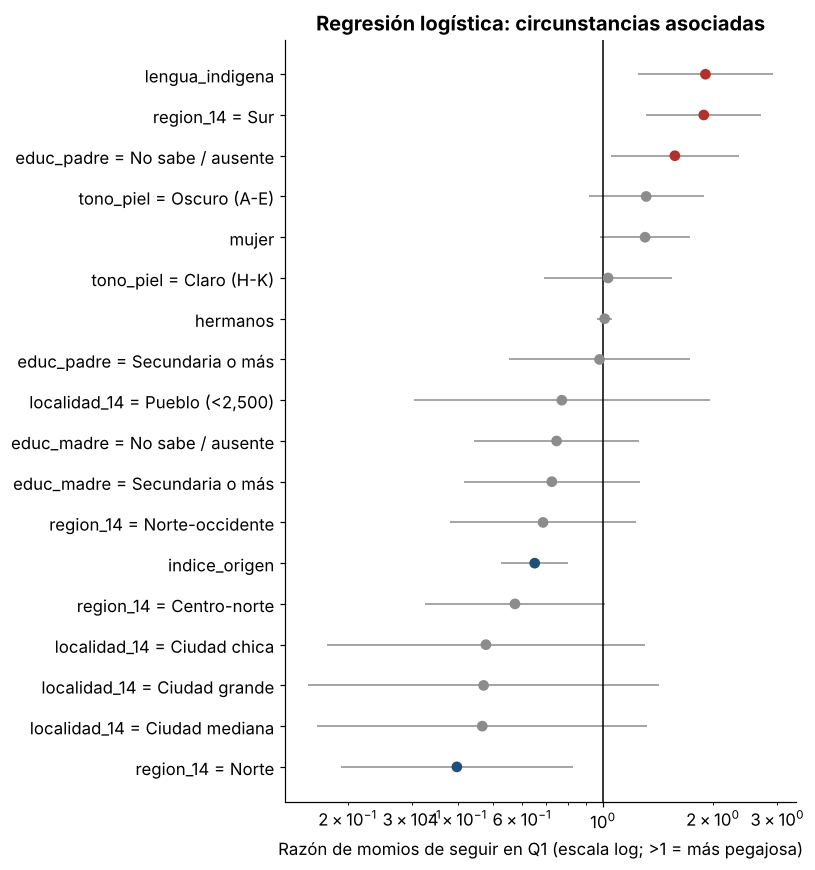

In [2]:
or_, m = I.logit_explicativo(q1)
or_.to_csv(TABLES / "razones_momios.csv"); display(or_); V.razones_momios(or_); plt.show()

**Cómo leer una razón de momios:** 1 = sin asociación; 1.9 = casi el doble de momios de seguir en Q1; 0.4 = 60% menos momios. Las comparaciones son contra: madre y padre con primaria o menos, metrópoli, región Centro, tono medio y cohorte 25-34.

,Variable,Pérdida de AUC,desv.
22,region_14,0.0712,0.0106
23,cohorte,0.0503,0.0122
0,indice_origen,0.0468,0.0078
25,autoadscripcion,0.0164,0.0052
18,educ_padre,0.0105,0.0045
6,lengua_indigena,0.0098,0.0051
21,localidad_14,0.0097,0.0044
14,o_p33e,0.0088,0.0015
4,personas_hogar_14,0.0082,0.0040
15,o_p33f,0.0080,0.0025


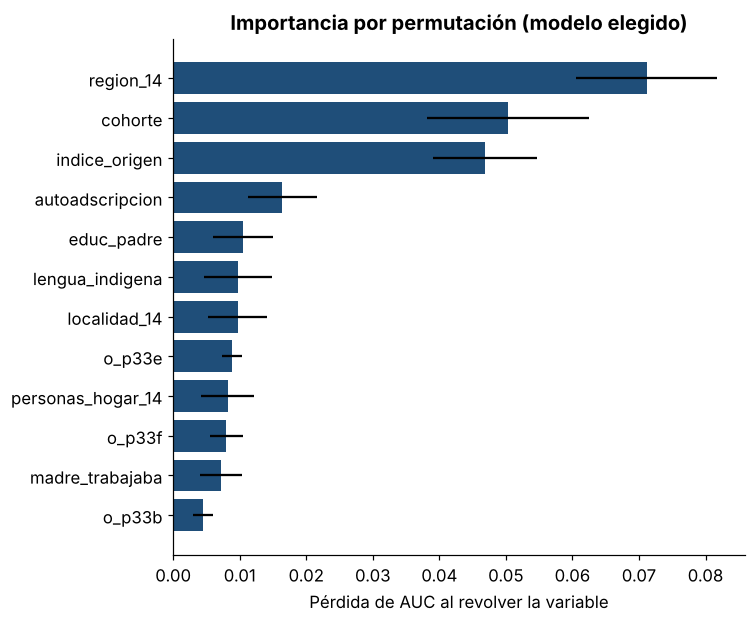

In [3]:
imp = I.importance(modelo, te, T.NUM, T.CAT)
imp.to_csv(TABLES / "importancia_permutacion.csv", index=False); display(imp.head(12)); V.importancia(imp); plt.show()

## SHAP (modelo complejo: gradient boosting)
Se usa para contrastar con el modelo interpretable.

,|SHAP| medio
region_14,0.5821
cohorte,0.4323
indice_origen,0.2025
autoadscripcion,0.1801
clase_padre,0.1442
lengua_indigena,0.1381
localidad_14,0.1354
personas_hogar_14,0.1284
educ_padre,0.1087
o_p33f,0.0977


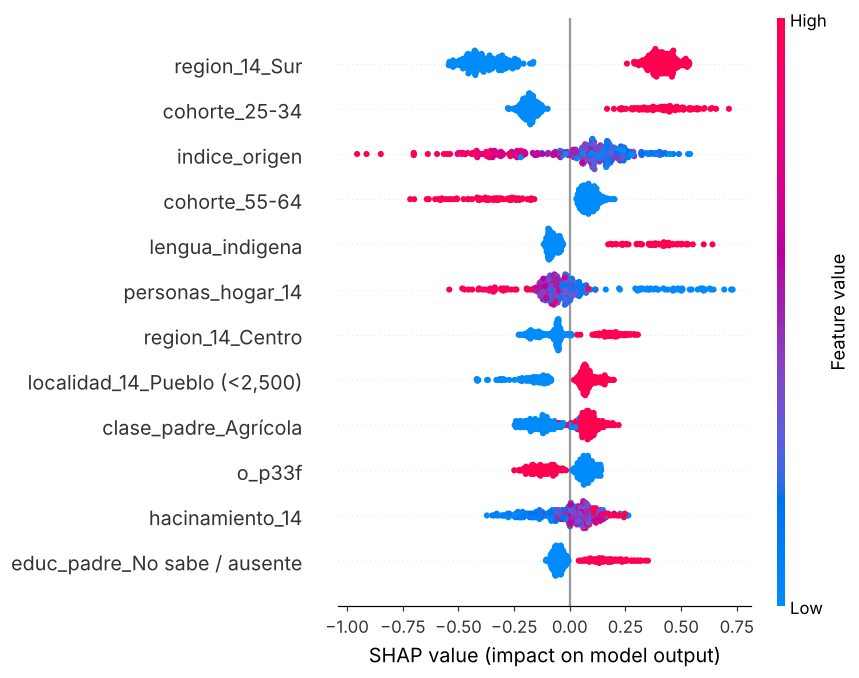

In [4]:
from src.evaluation import extra as X
import shap
gb = modelos["Gradient boosting"]
shap_imp, sv, Xs, names = X.shap_values(gb, te, T.NUM, T.CAT); shap_imp.to_csv(TABLES / "shap_importancia.csv"); display(shap_imp.head(12).to_frame("|SHAP| medio"))
shap.summary_plot(sv, Xs, feature_names=names, max_display=12, show=False); plt.gcf().savefig(FIGURES / "12_shap.png", bbox_inches="tight", dpi=200); plt.show()

## H003. ¿La asociación de la educación con salir de Q1 varía por región?

In [5]:
h3, w3 = X.h003_educacion_por_region(df); h3.to_csv(TABLES / "h003_educacion_por_region.csv"); display(h3); print(w3)

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


,% sigue Q1 | Secundaria o menos,% sigue Q1 | Prepa o más,n | Secundaria o menos,n | Prepa o más,Diferencia (pts)
region_14,,,,,
Centro,47.6,36.0,529.0,99.0,11.6
Centro-norte,36.4,15.6,181.0,57.0,20.8
Norte,22.7,24.0,165.0,32.0,-1.3
Norte-occidente,42.9,12.8,203.0,38.0,30.1
Sur,66.9,44.9,1114.0,211.0,21.9


{'p-valor conjunto de las interacciones (Wald)': 0.261}


**Lectura:** en la descripción, la ventaja de tener preparatoria o más va de ≈0 puntos en el Norte (n pequeña) a ≈30 en el Norte-occidente. Pero la prueba conjunta de las interacciones **no es significativa** (p ≈ 0.26) → **H003 SIN EVIDENCIA suficiente**. Haría falta más muestra por región.

## H005. Desventajas acumuladas: Sur + pueblo + lengua indígena

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


,% sigue Q1,n
n_desventajas,,
0,30.1,420.0
1,45.4,1128.0
2,61.6,873.0
3,82.0,253.0


{'p-valor conjunto de las interacciones (Wald)': 0.202, 'AIC aditivo': np.float64(3352.8), 'AIC con interacciones': np.float64(3344.7)}


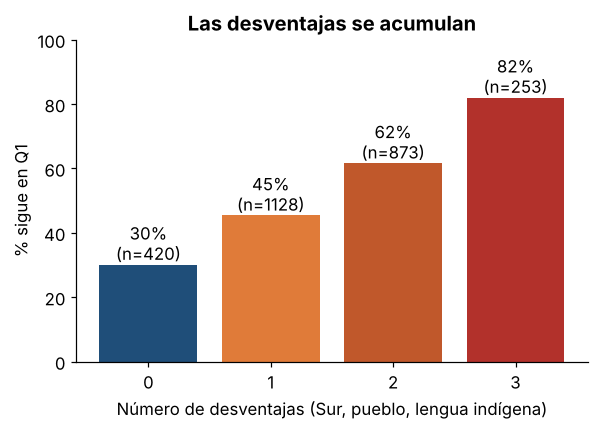

In [6]:
h5, w5 = X.h005_desventajas_acumuladas(df); h5.to_csv(TABLES / "h005_desventajas_acumuladas.csv"); display(h5); print(w5)
fig, ax = plt.subplots(figsize=(6, 3.8)); ax.bar(h5.index.astype(str), h5["% sigue Q1"], color=["#1f4e79", "#e07b39", "#c0582b", "#b2312b"])
for i, (v, n) in enumerate(zip(h5["% sigue Q1"], h5["n"])): ax.text(i, v + 1.5, f"{v:.0f}%\n(n={int(n)})", ha="center")
ax.set_xlabel("Número de desventajas (Sur, pueblo, lengua indígena)"); ax.set_ylabel("% sigue en Q1"); ax.set_ylim(0, 100); ax.set_title("Las desventajas se acumulan")
fig.savefig(FIGURES / "13_desventajas_acumuladas.png", bbox_inches="tight", dpi=200); plt.show()

**Lectura:** la persistencia sube de **30%** sin ninguna de las tres desventajas a **82%** con las tres. Pero las interacciones no son significativas (p ≈ 0.20): las desventajas **se suman**, no se multiplican → **H005 APOYADA PROVISIONALMENTE como acumulación aditiva; SIN EVIDENCIA de sinergia**.

## Análisis de errores del modelo elegido

In [7]:
ea = X.error_analysis(modelo, te, T.NUM, T.CAT); ea.to_csv(TABLES / "analisis_errores.csv"); display(ea)

,n,% Sur,% pueblo,% lengua indígena,% tono oscuro,% prepa o más (no usado por el modelo)
tipo,,,,,,
Acierto,359,51.5,66.3,21.7,20.3,16.2
Falso negativo (sigue y se predijo que sale),87,16.1,64.4,1.1,29.9,17.2
Falso positivo (sale y se predijo que sigue),89,69.7,69.7,29.2,16.9,18.0


**Lectura:** los falsos negativos (personas que siguen en Q1 pero el modelo predijo que salían) son casi todos **de fuera del Sur** (16% del Sur) y tienen más tono oscuro (30%). Es la misma heterogeneidad del análisis de Simpson: fuera del Sur, el tono de piel separa trayectorias que el modelo no capta.

## Perfiles (K-Means, solo ilustrativos)

In [8]:
pk = X.perfiles_kmeans(df); pk.to_csv(TABLES / "perfiles_kmeans.csv"); display(pk)

,indice_origen,sur,pueblo,lengua_indigena,padre_ausente,madre_trabajaba,hacinamiento_14,n,% sigue Q1
perfil,,,,,,,,,
3,-4.5,72.2,76.4,100.0,16.4,20.4,5.6,475,69.0
2,-4.4,55.1,66.7,0.2,100.0,40.4,5.1,586,58.2
0,-4.3,43.5,100.0,0.0,0.0,21.8,5.3,1048,47.5
1,-3.9,41.2,0.0,0.0,0.0,27.4,4.8,565,35.7


**Lectura:** surgen 4 perfiles: (1) indígena, rural y del Sur → **69%** sigue en Q1; (2) padre ausente → 58%; (3) rural sin otras desventajas → 48%; (4) urbano → **36%**. Son perfiles descriptivos, no tipos causales.

## Tabla de convergencia de evidencia (formato del roadmap)
| Conclusión candidata | EDA | Modelo interpretable | Modelo complejo (SHAP) | Subgrupos | Literatura | Nivel de confianza |
|---|---|---|---|---|---|---|
| La pobreza es pegajosa (≈ 1 de cada 2 sigue en Q1) | ✅ 51% | — | — | ✅ robusto con 3 definiciones | ✅ CEEY (orden de magnitud similar; verificar cifra exacta) | **Alto** |
| Crecer en el Sur aumenta la persistencia | ✅ 64% vs 23% | ✅ RM 1.9 | ✅ n.º 1 | ✅ | ✅ CEEY reporta brechas regionales | **Alto** |
| Lengua indígena se asocia con más persistencia | ✅ 69% vs 47% | ✅ RM 1.9 | ✅ top 6 | ✅ calibrado | ✅ | **Alto** |
| Las desventajas se acumulan | ✅ 30% → 82% | ✅ aditivo | — | n = 253 con las 3 | — | **Medio-alto** |
| La educación propia es la principal vía de salida | ✅ 56% → 18% | ✅ (mediación AUC 0.70 → 0.74) | — | ⚠️ H003 sin evidencia de variación regional | ✅ | **Medio** (mediadora, no es origen) |
| Movilidad educativa ≠ movilidad económica | ✅ 43% sigue | — | — | — | — | **Medio** |
| Tono de piel | ⚠️ solo fuera del Sur | ❌ no significativo | bajo | ❌ modelo mal calibrado | ✅ CEEY y literatura sobre tono de piel | **Bajo / heterogéneo** |
| Cohortes jóvenes más atrapadas | ✅ | ✅ | ✅ n.º 2 | — | — | **Bajo** (posible artefacto de medición) |
| Escolaridad de la madre (dentro de Q1) | débil | ❌ | bajo | — | — | **Sin evidencia** (casi no hay variación) |

**Para revisión humana:** el modelo interpretable y el complejo coinciden en las 3 variables principales (región, cohorte e índice de origen). No hay conclusiones contradictorias entre modelos.

**Estado de la fase:** PROPUESTA — falta la revisión humana (regla de avance del roadmap: APROBADA / APROBADA CON CAMBIOS / REABRIR / BLOQUEADA).